# Robustness of metrics to clustering algorithm


In [1]:
import os
os.environ["R_HOME"] = "/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/R"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import math
import colorcet as cc
from scipy.stats import wilcoxon, ttest_rel
from statsmodels.stats.multitest import multipletests
# import kendall_w as kw
from itertools import combinations

import matplotlib.font_manager as font_manager

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

In [2]:
import rpy2.robjects as robjects
from rpy2.robjects import conversion, default_converter
from rpy2.robjects.pandas2ri import converter as pandas_converter

In [3]:
ordered_metrics = [
    'MCC', 'F1', 'JACC', 'PURITY', 'HOMO', 'CCENT', # Cluster-as-prediction
    'COMP', # Joint bio&batch
    'BAMI', 'BVM', 'BARI', 'AMI', 'NMI', 'VM', 'AWC', 'ARI', 'VI', 'FMI', # Cluster-label similarity
    'CLUSTASW', 'CLUSTCH', 'CLUSTDBI', 'MODULARITY', 'COMPACT', 'SEPARATION', # Independent cluster metrics
    'BATCHARI', 'BCENT', 'BP', 'CRE' # Batch metrics
]

batch_metrics = ['BATCHARI', 'BCENT', 'BP', 'CRE']

In [4]:
def compute_tau_across_integrations(df):
    with conversion.localconverter(default_converter + pandas_converter):
        robjects.globalenv['df_sub'] = conversion.py2rpy(df[['Metric', 'Integration', 'clustering_type', "Value"]])
        w = robjects.r('''
library(dplyr)
library(tidyr)
library(purrr)

all_tau <- df_sub %>%
  group_by(Metric) %>%
  group_modify(~ {
    sub <- .x
    clustering_types <- unique(sub$clustering_type)
    combos <- combn(clustering_types, 2, simplify = FALSE)
    
    map_dfr(combos, function(pair) {
      c1 <- pair[1]
      c2 <- pair[2]
      
      common_integrations <- intersect(
        sub$Integration[sub$clustering_type == c1],
        sub$Integration[sub$clustering_type == c2]
      )
      
      sub1 <- sub %>%
        filter(Integration %in% common_integrations, clustering_type == c1) %>%
        arrange(Integration) %>%
        mutate(Rank = rank(Value))
      
      sub2 <- sub %>%
        filter(Integration %in% common_integrations, clustering_type == c2) %>%
        arrange(Integration) %>%
        mutate(Rank = rank(Value))

      tau_result <- cor.test(sub1$Rank, sub2$Rank, method = "kendall")
      
      tibble(
        Algo1   = c1,
        Algo2   = c2,
        tau     = tau_result$estimate,
        p_value = tau_result$p.value
      )
    })
  }) %>%
  ungroup()

all_tau
    ''')
        return conversion.rpy2py(w)

## Collect all the data from the eight different datasets


The combined metric file is available as `robustness_clustering_algorithm.csv`. To reproduce the Kendall's W or $\tau$, instead of using the code to load the CSV files, instead subset the metric file to the given dataset. e.g.

```Python
df_full = pd.read_csv('../data/source_data/robustness_clustering_algorithm.csv')
df_sub = df_full[df_full['Dataset'] == 'neurips_bmmc']
```


###  NeurIPS BMMC

In [5]:
df = pd.concat([
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_neurips_bmmc/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_neurips_bmmc_rescue/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_neurips_bmmc/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/kmeans_neurips_bmmc/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/gmm_neurips_bmmc/metrics/all-metrics.csv')
])

df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", 'clustering_type', "Dataset"],keep='first'
)
df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({ # There will be a lot of this renaming post-hoc.
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[(df.neighbor_type == 'default') | df.neighbor_type.isna()]
df = df[~df.Metric.isin(['CLUSTACC', 'ISOF1'])]
df_sub = df[(df.neighbor_k == 15) | df.neighbor_k.isna()]

df_sub['val_rank'] = df_sub.groupby(['Dataset', 'Integration', 'Metric'])['Value'].rank(
    ascending=False,  # Use False if higher Value is better (Rank 1), True if lower is better
    method='min'      # Determines how ties are handled (e.g., 'min', 'dense', 'average')
)

/tmp/ipykernel_2191697/2063694502.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sub['val_rank'] = df_sub.groupby(['Dataset', 'Integration', 'Metric'])['Value'].rank(


In [ ]:
label_order = ['leiden', 'louvain', 'kmeans', 'gmm']
df_sub['clustering_type'] = pd.Categorical(df_sub['clustering_type'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'clustering_type'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)

num_rows = math.ceil(num_metrics / NUM_COLS)
fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='clustering_type',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('Clustering algorithm', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()

plt.show()

In [6]:
w_results_1 = compute_tau_across_integrations(df_sub)
w_results_1['Dataset'] = "neurips_bmmc"
w_results_1

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/rpy2/robjects/pandas2ri.py:56: UserWarning: DataFrame contains duplicated elements in the index, which will lead to loss of the row names in the resulting data.frame
  warnings.warn('DataFrame contains duplicated elements in the index, '
R callback write-console: 
Attaching package: ‘dplyr’

  
R callback write-console: The following objects are masked from ‘package:stats’:

    filter, lag

  
R callback write-console: The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union

  
R callback write-console: In addition:   
R callback write-console: Warning messages:
  
R callback write-console: 1:   
R callback write-console: In cor.test.default(sub1$Rank, sub2$Rank, method = "kendall") :  
R callback write-console: 
   
R callback write-console:  Cannot compute exact p-value with ties
  
R callback write-console: 2:   
R callback write-console: In cor.test

,Metric,Algo1,Algo2,tau,p_value,Dataset
1,AMI,leiden,louvain,0.906907,4.218847e-15,neurips_bmmc
2,AMI,leiden,kmeans,0.777778,7.105427e-15,neurips_bmmc
3,AMI,leiden,gmm,0.670588,4.790930e-10,neurips_bmmc
4,AMI,louvain,kmeans,0.756757,4.285461e-14,neurips_bmmc
5,AMI,louvain,gmm,0.636975,5.318458e-09,neurips_bmmc
...,...,...,...,...,...,...
158,VM,leiden,kmeans,0.777778,7.105427e-15,neurips_bmmc
159,VM,leiden,gmm,0.670588,4.790930e-10,neurips_bmmc
160,VM,louvain,kmeans,0.756757,4.285461e-14,neurips_bmmc
161,VM,louvain,gmm,0.636975,5.318458e-09,neurips_bmmc


In [7]:
df_1 = df_sub.copy()

### Human pancreas

In [8]:
df = pd.concat([
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_human_pancreas/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_human_pancreas_rescue/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_human_pancreas/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_human_pancreas_rescue/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/kmeans_human_pancreas/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/gmm_human_pancreas/metrics/all-metrics.csv')
])

df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", 'clustering_type', "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[(df.neighbor_type == 'default') | df.neighbor_type.isna()]
df = df[~df.Metric.isin(['CLUSTACC', 'ISOF1'])]

df_sub = df[(df.neighbor_k == 15) | df.neighbor_k.isna()]
df_sub['val_rank'] = df_sub.groupby(['Dataset', 'Integration', 'Metric'])['Value'].rank(
    ascending=False,  # Use False if higher Value is better (Rank 1), True if lower is better
    method='min'      # Determines how ties are handled (e.g., 'min', 'dense', 'average')
)

/tmp/ipykernel_2191697/1846003551.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sub['val_rank'] = df_sub.groupby(['Dataset', 'Integration', 'Metric'])['Value'].rank(


In [ ]:
label_order = ['leiden', 'louvain', 'kmeans', 'gmm']
df_sub['clustering_type'] = pd.Categorical(df_sub['clustering_type'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'clustering_type'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)

num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='clustering_type',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles, 
    labels, 
    loc='upper center', 
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()

plt.show()

In [9]:
w_results_2 = compute_tau_across_integrations(df_sub)
w_results_2['Dataset'] = "human_pancreas"
w_results_2

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/rpy2/robjects/pandas2ri.py:56: UserWarning: DataFrame contains duplicated elements in the index, which will lead to loss of the row names in the resulting data.frame
  warnings.warn('DataFrame contains duplicated elements in the index, '
R callback write-console: In addition:   
R callback write-console: There were 19 warnings (use warnings() to see them)  
R callback write-console: 
  


,Metric,Algo1,Algo2,tau,p_value,Dataset
1,AMI,leiden,louvain,0.964912,-4.440892e-16,human_pancreas
2,AMI,leiden,kmeans,0.816464,-4.440892e-16,human_pancreas
3,AMI,leiden,gmm,0.749206,2.129408e-13,human_pancreas
4,AMI,louvain,kmeans,0.802969,-4.440892e-16,human_pancreas
5,AMI,louvain,gmm,0.736508,7.716050e-13,human_pancreas
...,...,...,...,...,...,...
158,VM,leiden,kmeans,0.816464,-4.440892e-16,human_pancreas
159,VM,leiden,gmm,0.752381,1.527667e-13,human_pancreas
160,VM,louvain,kmeans,0.800270,-4.440892e-16,human_pancreas
161,VM,louvain,gmm,0.739683,5.628831e-13,human_pancreas


In [10]:
df_2 = df_sub.copy()

###  scIB sim1

In [11]:
df = pd.concat([
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_scib_sim1/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_scib_sim1_rescue/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_scib_sim1/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_scib_sim1_rescue/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/kmeans_scib_sim1/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/gmm_scib_sim1/metrics/all-metrics.csv')
])

df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", 'clustering_type', "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[(df.neighbor_type == 'default') | df.neighbor_type.isna()]
df = df[~df.Metric.isin(['CLUSTACC', 'ISOF1'])]

df_sub = df[(df.neighbor_k == 15) | df.neighbor_k.isna()]
df_sub['val_rank'] = df_sub.groupby(['Dataset', 'Integration', 'Metric'])['Value'].rank(
    ascending=False,  # Use False if higher Value is better (Rank 1), True if lower is better
    method='min'      # Determines how ties are handled (e.g., 'min', 'dense', 'average')
)

/tmp/ipykernel_2191697/28357634.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sub['val_rank'] = df_sub.groupby(['Dataset', 'Integration', 'Metric'])['Value'].rank(


In [ ]:
label_order = ['leiden', 'louvain', 'kmeans', 'gmm']
df_sub['clustering_type'] = pd.Categorical(df_sub['clustering_type'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'clustering_type'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)

num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='clustering_type',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles, 
    labels, 
    loc='upper center', 
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()

plt.show()

In [12]:
w_results_3 = compute_tau_across_integrations(df_sub)
w_results_3['Dataset'] = "scib_sim1"
w_results_3

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/rpy2/robjects/pandas2ri.py:56: UserWarning: DataFrame contains duplicated elements in the index, which will lead to loss of the row names in the resulting data.frame
  warnings.warn('DataFrame contains duplicated elements in the index, '
R callback write-console: In addition:   
R callback write-console: There were 50 or more warnings (use warnings() to see the first 50)  
R callback write-console: 
  


,Metric,Algo1,Algo2,tau,p_value,Dataset
1,AMI,leiden,louvain,0.940171,3.896650e-13,scib_sim1
2,AMI,leiden,kmeans,0.786164,9.136119e-10,scib_sim1
3,AMI,leiden,gmm,0.809778,1.653268e-09,scib_sim1
4,AMI,louvain,kmeans,0.819887,1.697273e-10,scib_sim1
5,AMI,louvain,gmm,0.839047,4.195876e-10,scib_sim1
...,...,...,...,...,...,...
158,VM,leiden,kmeans,0.780013,1.073302e-09,scib_sim1
159,VM,leiden,gmm,0.801537,2.032074e-09,scib_sim1
160,VM,louvain,kmeans,0.813562,2.012371e-10,scib_sim1
161,VM,louvain,gmm,0.830596,5.212441e-10,scib_sim1


In [13]:
df_3 = df_sub.copy()

###  Mouse mammary

In [14]:
df = pd.concat([
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_mouse_mammary/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_mouse_mammary_rescue/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_mouse_mammary/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_mouse_mammary_rescue/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/kmeans_mouse_mammary/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/gmm_mouse_mammary/metrics/all-metrics.csv')
])

df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", 'clustering_type', "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[(df.neighbor_type == 'default') | df.neighbor_type.isna()]
df = df[~df.Metric.isin(['CLUSTACC', 'ISOF1'])]

df_sub = df[(df.neighbor_k == 15) | df.neighbor_k.isna()]
df_sub['val_rank'] = df_sub.groupby(['Dataset', 'Integration', 'Metric'])['Value'].rank(
    ascending=False,  # Use False if higher Value is better (Rank 1), True if lower is better
    method='min'      # Determines how ties are handled (e.g., 'min', 'dense', 'average')
)

/tmp/ipykernel_2191697/3181623180.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sub['val_rank'] = df_sub.groupby(['Dataset', 'Integration', 'Metric'])['Value'].rank(


In [ ]:
label_order = ['leiden', 'louvain', 'kmeans', 'gmm']
df_sub['clustering_type'] = pd.Categorical(df_sub['clustering_type'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'clustering_type'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)

num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='clustering_type',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles, 
    labels, 
    loc='upper center', 
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()

plt.show()

In [15]:
w_results_4 = compute_tau_across_integrations(df_sub)
w_results_4['Dataset'] = "mouse_mammary"
w_results_4

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/rpy2/robjects/pandas2ri.py:56: UserWarning: DataFrame contains duplicated elements in the index, which will lead to loss of the row names in the resulting data.frame
  warnings.warn('DataFrame contains duplicated elements in the index, '
R callback write-console: In addition:   
R callback write-console: There were 50 or more warnings (use warnings() to see the first 50)  
R callback write-console: 
  


,Metric,Algo1,Algo2,tau,p_value,Dataset
1,AMI,leiden,louvain,0.848276,2.442491e-15,mouse_mammary
2,AMI,leiden,kmeans,0.370115,3.697494e-03,mouse_mammary
3,AMI,leiden,gmm,0.319540,1.290351e-02,mouse_mammary
4,AMI,louvain,kmeans,0.328736,1.042266e-02,mouse_mammary
5,AMI,louvain,gmm,0.333333,9.346396e-03,mouse_mammary
...,...,...,...,...,...,...
158,VM,leiden,kmeans,0.370115,3.697494e-03,mouse_mammary
159,VM,leiden,gmm,0.319540,1.290351e-02,mouse_mammary
160,VM,louvain,kmeans,0.328736,1.042266e-02,mouse_mammary
161,VM,louvain,gmm,0.333333,9.346396e-03,mouse_mammary


In [16]:
df_4 = df_sub.copy()

### Human PBMC seq techs

In [17]:
df = pd.concat([
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_human_pbmc_seq_techs/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_human_pbmc_seq_techs/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_human_pbmc_seq_techs_rescue/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/kmeans_human_pbmc_seq_techs/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/gmm_human_pbmc_seq_techs/metrics/all-metrics.csv')
])

df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", 'clustering_type', "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[(df.neighbor_type == 'default') | df.neighbor_type.isna()]
df = df[~df.Metric.isin(['CLUSTACC', 'ISOF1'])]

df_sub = df[(df.neighbor_k == 15) | df.neighbor_k.isna()]
df_sub['val_rank'] = df_sub.groupby(['Dataset', 'Integration', 'Metric'])['Value'].rank(
    ascending=False,  # Use False if higher Value is better (Rank 1), True if lower is better
    method='min'      # Determines how ties are handled (e.g., 'min', 'dense', 'average')
)

/tmp/ipykernel_2191697/2548472818.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sub['val_rank'] = df_sub.groupby(['Dataset', 'Integration', 'Metric'])['Value'].rank(


In [ ]:
label_order = ['leiden', 'louvain', 'kmeans', 'gmm']
df_sub['clustering_type'] = pd.Categorical(df_sub['clustering_type'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'clustering_type'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)

num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='clustering_type',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles, 
    labels, 
    loc='upper center', 
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()

plt.show()

In [18]:
w_results_5 = compute_tau_across_integrations(df_sub)
w_results_5['Dataset'] = "human_pbmc_seq_techs"
w_results_5

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/rpy2/robjects/pandas2ri.py:56: UserWarning: DataFrame contains duplicated elements in the index, which will lead to loss of the row names in the resulting data.frame
  warnings.warn('DataFrame contains duplicated elements in the index, '
R callback write-console: In addition:   
R callback write-console: There were 25 warnings (use warnings() to see them)  
R callback write-console: 
  


,Metric,Algo1,Algo2,tau,p_value,Dataset
1,AMI,leiden,louvain,0.939683,-1.776357e-15,human_pbmc_seq_techs
2,AMI,leiden,kmeans,0.809524,-1.776357e-15,human_pbmc_seq_techs
3,AMI,leiden,gmm,0.741176,1.146860e-12,human_pbmc_seq_techs
4,AMI,louvain,kmeans,0.825397,-1.776357e-15,human_pbmc_seq_techs
5,AMI,louvain,gmm,0.731092,2.988054e-12,human_pbmc_seq_techs
...,...,...,...,...,...,...
158,VM,leiden,kmeans,0.809524,-1.776357e-15,human_pbmc_seq_techs
159,VM,leiden,gmm,0.741176,1.146860e-12,human_pbmc_seq_techs
160,VM,louvain,kmeans,0.825397,-1.776357e-15,human_pbmc_seq_techs
161,VM,louvain,gmm,0.731092,2.988054e-12,human_pbmc_seq_techs


In [19]:
df_5 = df_sub.copy()

### Cellranger versions

In [20]:
df = pd.concat([
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_cellranger_versions/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_cellranger_versions_rescue/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_cellranger_versions/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_cellranger_versions_rescue/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/kmeans_cellranger_versions/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/gmm_cellranger_versions/metrics/all-metrics.csv')
])

df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", 'clustering_type', "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[(df.neighbor_type == 'default') | df.neighbor_type.isna()]
df = df[~df.Metric.isin(['CLUSTACC', 'ISOF1'])]

df_sub = df[(df.neighbor_k == 15) | df.neighbor_k.isna()]
df_sub['val_rank'] = df_sub.groupby(['Dataset', 'Integration', 'Metric'])['Value'].rank(
    ascending=False,  # Use False if higher Value is better (Rank 1), True if lower is better
    method='min'      # Determines how ties are handled (e.g., 'min', 'dense', 'average')
)

/tmp/ipykernel_2191697/596152630.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sub['val_rank'] = df_sub.groupby(['Dataset', 'Integration', 'Metric'])['Value'].rank(


In [ ]:
label_order = ['leiden', 'louvain', 'kmeans', 'gmm']
df_sub['clustering_type'] = pd.Categorical(df_sub['clustering_type'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'clustering_type'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)

num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='clustering_type',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles, 
    labels, 
    loc='upper center', 
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()

plt.show()

In [21]:
w_results_6 = compute_tau_across_integrations(df_sub)
w_results_6['Dataset'] = "cellranger_versions"
w_results_6

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/rpy2/robjects/pandas2ri.py:56: UserWarning: DataFrame contains duplicated elements in the index, which will lead to loss of the row names in the resulting data.frame
  warnings.warn('DataFrame contains duplicated elements in the index, '
R callback write-console: In addition:   
R callback write-console: There were 50 or more warnings (use warnings() to see the first 50)  
R callback write-console: 
  


,Metric,Algo1,Algo2,tau,p_value,Dataset
1,AMI,leiden,louvain,0.857550,3.747145e-14,cellranger_versions
2,AMI,leiden,kmeans,0.657651,6.296766e-09,cellranger_versions
3,AMI,leiden,gmm,0.671962,8.303793e-09,cellranger_versions
4,AMI,louvain,kmeans,0.646264,1.142471e-08,cellranger_versions
5,AMI,louvain,gmm,0.637014,4.695144e-08,cellranger_versions
...,...,...,...,...,...,...
158,VM,leiden,kmeans,0.657651,6.296766e-09,cellranger_versions
159,VM,leiden,gmm,0.671962,8.303793e-09,cellranger_versions
160,VM,louvain,kmeans,0.646264,1.142471e-08,cellranger_versions
161,VM,louvain,gmm,0.637014,4.695144e-08,cellranger_versions


In [22]:
df_6 = df_sub.copy()

### NPH cerebellum

In [23]:
df = pd.concat([
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_nph_cerebellum/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_nph_cerebellum/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/kmeans_nph_cerebellum/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/gmm_nph_cerebellum/metrics/all-metrics.csv')
])

df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", 'clustering_type', "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[(df.neighbor_type == 'default') | df.neighbor_type.isna()]
df = df[~df.Metric.isin(['CLUSTACC', 'ISOF1'])]

df_sub = df[(df.neighbor_k == 15) | df.neighbor_k.isna()]
df_sub['val_rank'] = df_sub.groupby(['Dataset', 'Integration', 'Metric'])['Value'].rank(
    ascending=False,  # Use False if higher Value is better (Rank 1), True if lower is better
    method='min'      # Determines how ties are handled (e.g., 'min', 'dense', 'average')
)

/tmp/ipykernel_2191697/4037419660.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sub['val_rank'] = df_sub.groupby(['Dataset', 'Integration', 'Metric'])['Value'].rank(


In [ ]:
label_order = ['leiden', 'louvain', 'kmeans', 'gmm']
df_sub['clustering_type'] = pd.Categorical(df_sub['clustering_type'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'clustering_type'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)

num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='clustering_type',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles, 
    labels, 
    loc='upper center', 
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()

plt.show()

In [24]:
w_results_7 = compute_tau_across_integrations(df_sub)
w_results_7['Dataset'] = "nph_cerebellum"
w_results_7

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/rpy2/robjects/pandas2ri.py:56: UserWarning: DataFrame contains duplicated elements in the index, which will lead to loss of the row names in the resulting data.frame
  warnings.warn('DataFrame contains duplicated elements in the index, '
R callback write-console: In addition:   
R callback write-console: There were 15 warnings (use warnings() to see them)  
R callback write-console: 
  


,Metric,Algo1,Algo2,tau,p_value,Dataset
1,AMI,leiden,louvain,0.767742,3.357536e-12,nph_cerebellum
2,AMI,leiden,kmeans,0.251613,4.803736e-02,nph_cerebellum
3,AMI,leiden,gmm,0.522581,1.623401e-05,nph_cerebellum
4,AMI,louvain,kmeans,0.234409,6.609182e-02,nph_cerebellum
5,AMI,louvain,gmm,0.513978,2.325567e-05,nph_cerebellum
...,...,...,...,...,...,...
158,VM,leiden,kmeans,0.251613,4.803736e-02,nph_cerebellum
159,VM,leiden,gmm,0.522581,1.623401e-05,nph_cerebellum
160,VM,louvain,kmeans,0.234409,6.609182e-02,nph_cerebellum
161,VM,louvain,gmm,0.513978,2.325567e-05,nph_cerebellum


In [25]:
df_7 = df_sub.copy()

### Seurat PBMC

In [26]:
df = pd.concat([
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_seurat_pbmc/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_seurat_pbmc/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/kmeans_seurat_pbmc/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/gmm_seurat_pbmc/metrics/all-metrics.csv')
])

df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", 'clustering_type', "Dataset"],keep='first'
)
df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[(df.neighbor_type == 'default') | df.neighbor_type.isna()]
df = df[~df.Metric.isin(['CLUSTACC', 'ISOF1'])]

df_sub = df[(df.neighbor_k == 15) | df.neighbor_k.isna()]
df_sub['val_rank'] = df_sub.groupby(['Dataset', 'Integration', 'Metric'])['Value'].rank(
    ascending=False,
    method='min'
)

/tmp/ipykernel_2191697/3929409460.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sub['val_rank'] = df_sub.groupby(['Dataset', 'Integration', 'Metric'])['Value'].rank(


In [ ]:
label_order = ['leiden', 'louvain', 'kmeans', 'gmm']
df_sub['clustering_type'] = pd.Categorical(df_sub['clustering_type'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'clustering_type'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)

num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='clustering_type',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles, 
    labels, 
    loc='upper center', 
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()

plt.show()

In [27]:
w_results_8 = compute_tau_across_integrations(df_sub)
w_results_8['Dataset'] = "seurat_pbmc"
w_results_8

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/rpy2/robjects/pandas2ri.py:56: UserWarning: DataFrame contains duplicated elements in the index, which will lead to loss of the row names in the resulting data.frame
  warnings.warn('DataFrame contains duplicated elements in the index, '
R callback write-console: In addition:   
R callback write-console: There were 27 warnings (use warnings() to see them)  
R callback write-console: 
  


,Metric,Algo1,Algo2,tau,p_value,Dataset
1,AMI,leiden,louvain,0.900901,4.218847e-15,seurat_pbmc
2,AMI,leiden,kmeans,0.654655,4.536620e-10,seurat_pbmc
3,AMI,leiden,gmm,0.639929,7.769739e-09,seurat_pbmc
4,AMI,louvain,kmeans,0.687688,3.148037e-11,seurat_pbmc
5,AMI,louvain,gmm,0.607843,5.880445e-08,seurat_pbmc
...,...,...,...,...,...,...
158,VM,leiden,kmeans,0.654655,4.536620e-10,seurat_pbmc
159,VM,leiden,gmm,0.639929,7.769739e-09,seurat_pbmc
160,VM,louvain,kmeans,0.687688,3.148037e-11,seurat_pbmc
161,VM,louvain,gmm,0.607843,5.880445e-08,seurat_pbmc


In [28]:
df_8 = df_sub.copy()

## Combine $\tau$'s

In [29]:
w_results = pd.concat([w_results_1, w_results_2, w_results_3, w_results_4, w_results_5, w_results_6, w_results_7, w_results_8])
w_results.reset_index(drop=True, inplace=True)

### Aggregate by comparison

In [30]:
w_results.groupby(['Algo1', 'Algo2'])['tau'].mean()

Algo1    Algo2  
kmeans   gmm        0.726782
leiden   gmm        0.587814
         kmeans     0.623988
         louvain    0.888481
louvain  gmm        0.596991
         kmeans     0.627578
Name: tau, dtype: float64

### Individual comparisons between pairs of clustering algorithms

/tmp/ipykernel_3719369/1900660169.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


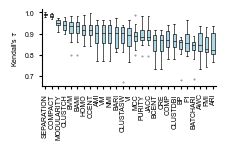

In [31]:
# Concordance between Leiden and Louvain
leid_louv = w_results[(w_results['Algo1'] == 'leiden') & (w_results['Algo2'] == 'louvain')]
order = leid_louv.groupby("Metric")["tau"].median().sort_values(ascending=False).index

boxplot_data = [leid_louv[leid_louv["Metric"] == metric]["tau"].values for metric in order]

fig, ax = plt.subplots(figsize=(2.4, 1.6))

ax.boxplot(
    boxplot_data, 
    labels=order, 
    patch_artist=True,  # Allows filling the boxes with color
    boxprops=dict(facecolor="lightblue", color="black", linewidth=.45),
    medianprops=dict(color="black", linewidth=.45),
    whiskerprops=dict(color="black", linewidth=.45),
    capprops=dict(color="black", linewidth=.45),
    flierprops=dict(marker="o", markerfacecolor="lightblue", markersize=.95, markeredgecolor='gray', markeredgewidth=0.4)
)
ax.tick_params(axis='both', labelsize=5, length=2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_ylabel("Kendall's $\\tau$", fontsize=5)
plt.xticks(rotation=90, fontsize=5)
plt.tight_layout()
# plt.savefig('../publication_figures/clustering_algo_leiden_louvain_tau.png', dpi=300, bbox_inches='tight')
plt.show()

In [32]:
leid_louv.groupby("Metric")['tau'].mean().sort_values()

Metric
BATCHARI      0.826760
BP            0.832318
FMI           0.838888
ARI           0.843118
CRE           0.845217
BCENT         0.845440
AWC           0.850765
CLUSTDBI      0.862060
F1            0.862869
COMP          0.868236
CLUSTASW      0.869031
VI            0.880833
MCC           0.886823
PURITY        0.890236
JACC          0.890236
VM            0.890430
NMI           0.890430
AMI           0.890768
BARI          0.891521
HOMO          0.916893
BVM           0.917274
BAMI          0.917589
CCENT         0.918183
CLUSTCH       0.938983
MODULARITY    0.949412
COMPACT       0.984256
SEPARATION    0.990412
Name: tau, dtype: float64

/tmp/ipykernel_3719369/1516881347.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


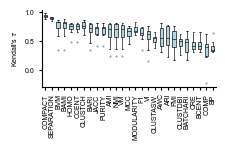

In [33]:
# Concordance between Leiden and K-means
leid_kmeans = w_results[(w_results['Algo1'] == 'leiden') & (w_results['Algo2'] == 'kmeans') & ~w_results['tau'].isna()]
order = leid_kmeans.groupby("Metric")["tau"].median().sort_values(ascending=False).index

boxplot_data = [leid_kmeans[leid_kmeans["Metric"] == metric]["tau"].values for metric in order]

fig, ax = plt.subplots(figsize=(2.4, 1.6))

ax.boxplot(
    boxplot_data, 
    labels=order, 
    patch_artist=True,  # Allows filling the boxes with color
    boxprops=dict(facecolor="lightblue", color="black", linewidth=.45),
    medianprops=dict(color="black", linewidth=.45),
    whiskerprops=dict(color="black", linewidth=.45),
    capprops=dict(color="black", linewidth=.45),
    flierprops=dict(marker="o", markerfacecolor="lightblue", markersize=.95, markeredgecolor='gray', markeredgewidth=0.4)
)
ax.tick_params(axis='both', labelsize=5, length=2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_ylabel("Kendall's $\\tau$", fontsize=5)
plt.xticks(rotation=90, fontsize=5)
plt.tight_layout()
# plt.savefig('../publication_figures/clustering_algo_leiden_kmeans_tau.png', dpi=300, bbox_inches='tight')
plt.show()

In [34]:
leid_kmeans.groupby("Metric")['tau'].mean().sort_values()

Metric
COMP          0.328125
BP            0.399812
BATCHARI      0.437557
CRE           0.441254
BCENT         0.441377
CLUSTDBI      0.476004
FMI           0.526460
CLUSTASW      0.538275
ARI           0.559872
VI            0.566192
AWC           0.567364
F1            0.630976
VM            0.639727
AMI           0.640496
NMI           0.640496
MCC           0.654751
BARI          0.677797
PURITY        0.682528
JACC          0.682528
MODULARITY    0.701784
CCENT         0.734976
HOMO          0.735488
BAMI          0.742498
BVM           0.743623
CLUSTCH       0.766133
SEPARATION    0.896751
COMPACT       0.936731
Name: tau, dtype: float64

/tmp/ipykernel_3719369/2768826865.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


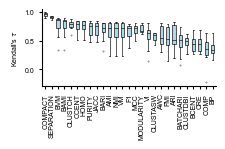

In [35]:
# Concordance between Louvain and K-means
louv_kmeans = w_results[(w_results['Algo1'] == 'louvain') & (w_results['Algo2'] == 'kmeans') & ~w_results['tau'].isna()]
order = louv_kmeans.groupby("Metric")["tau"].median().sort_values(ascending=False).index

boxplot_data = [louv_kmeans[louv_kmeans["Metric"] == metric]["tau"].values for metric in order]

fig, ax = plt.subplots(figsize=(2.4, 1.6))

ax.boxplot(
    boxplot_data, 
    labels=order, 
    patch_artist=True,  # Allows filling the boxes with color
    boxprops=dict(facecolor="lightblue", color="black", linewidth=.45),
    medianprops=dict(color="black", linewidth=.45),
    whiskerprops=dict(color="black", linewidth=.45),
    capprops=dict(color="black", linewidth=.45),
    flierprops=dict(marker="o", markerfacecolor="lightblue", markersize=.95, markeredgecolor='gray', markeredgewidth=0.4)
)
ax.tick_params(axis='both', labelsize=5, length=2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_ylabel("Kendall's $\\tau$", fontsize=5)
plt.xticks(rotation=90, fontsize=5)
plt.tight_layout()
# plt.savefig('../publication_figures/clustering_algo_louvain_kmeans_tau.png', dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_3719369/2455488133.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


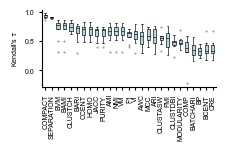

In [36]:
# Concordance between Leiden and GMM
leiden_gmm = w_results[(w_results['Algo1'] == 'leiden') & (w_results['Algo2'] == 'gmm') & ~w_results['tau'].isna()]
order = leiden_gmm.groupby("Metric")["tau"].median().sort_values(ascending=False).index

boxplot_data = [leiden_gmm[leiden_gmm["Metric"] == metric]["tau"].values for metric in order]

fig, ax = plt.subplots(figsize=(2.4, 1.6))

ax.boxplot(
    boxplot_data, 
    labels=order, 
    patch_artist=True,  # Allows filling the boxes with color
    boxprops=dict(facecolor="lightblue", color="black", linewidth=.45),
    medianprops=dict(color="black", linewidth=.45),
    whiskerprops=dict(color="black", linewidth=.45),
    capprops=dict(color="black", linewidth=.45),
    flierprops=dict(marker="o", markerfacecolor="lightblue", markersize=.95, markeredgecolor='gray', markeredgewidth=0.4)
)
ax.tick_params(axis='both', labelsize=5, length=2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_ylabel("Kendall's $\\tau$", fontsize=5)
plt.xticks(rotation=90, fontsize=5)
plt.tight_layout()
# plt.savefig('../publication_figures/clustering_algo_leiden_gmm_tau.png', dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_3719369/2169533347.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


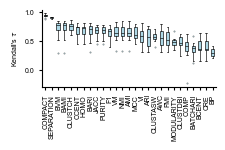

In [37]:
# Concordance between Louvain and GMM
louv_gmm = w_results[(w_results['Algo1'] == 'louvain') & (w_results['Algo2'] == 'gmm') & ~w_results['tau'].isna()]
order = louv_gmm.groupby("Metric")["tau"].median().sort_values(ascending=False).index

boxplot_data = [louv_gmm[louv_gmm["Metric"] == metric]["tau"].values for metric in order]

fig, ax = plt.subplots(figsize=(2.4, 1.6))

ax.boxplot(
    boxplot_data, 
    labels=order, 
    patch_artist=True,  # Allows filling the boxes with color
    boxprops=dict(facecolor="lightblue", color="black", linewidth=.45),
    medianprops=dict(color="black", linewidth=.45),
    whiskerprops=dict(color="black", linewidth=.45),
    capprops=dict(color="black", linewidth=.45),
    flierprops=dict(marker="o", markerfacecolor="lightblue", markersize=.95, markeredgecolor='gray', markeredgewidth=0.4)
)
ax.tick_params(axis='both', labelsize=5, length=2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_ylabel("Kendall's $\\tau$", fontsize=5)
plt.xticks(rotation=90, fontsize=5)
plt.tight_layout()
# plt.savefig('../publication_figures/clustering_algo_louvain_gmm_tau.png', dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_3719369/2223937208.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


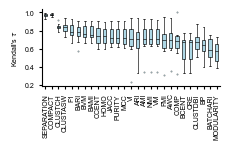

In [38]:
# Concordance between K-Means and GMM
kmeans_gmm = w_results[(w_results['Algo1'] == 'kmeans') & (w_results['Algo2'] == 'gmm') & ~w_results['tau'].isna()]
order = kmeans_gmm.groupby("Metric")["tau"].median().sort_values(ascending=False).index

boxplot_data = [kmeans_gmm[kmeans_gmm["Metric"] == metric]["tau"].values for metric in order]

fig, ax = plt.subplots(figsize=(2.4, 1.6))

ax.boxplot(
    boxplot_data, 
    labels=order, 
    patch_artist=True,  # Allows filling the boxes with color
    boxprops=dict(facecolor="lightblue", color="black", linewidth=.45),
    medianprops=dict(color="black", linewidth=.45),
    whiskerprops=dict(color="black", linewidth=.45),
    capprops=dict(color="black", linewidth=.45),
    flierprops=dict(marker="o", markerfacecolor="lightblue", markersize=.95, markeredgecolor='gray', markeredgewidth=0.4)
)
ax.tick_params(axis='both', labelsize=5, length=2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_ylabel("Kendall's $\\tau$", fontsize=5)
plt.xticks(rotation=90, fontsize=5)
plt.tight_layout()
# plt.savefig('../publication_figures/clustering_algo_kmeans_gmm_tau.png', dpi=300, bbox_inches='tight')
plt.show()

### Average Kendall's $\tau$ between each pair of clustering algorithms

In [39]:
avgs = pd.concat([
    leid_louv.groupby(['Metric', 'Algo1', 'Algo2'])['tau'].mean(),
    leid_kmeans.groupby(['Metric', 'Algo1', 'Algo2'])['tau'].mean(),
    leiden_gmm.groupby(['Metric', 'Algo1', 'Algo2'])['tau'].mean(),
    louv_kmeans.groupby(['Metric', 'Algo1', 'Algo2'])['tau'].mean(),
    louv_gmm.groupby(['Metric', 'Algo1', 'Algo2'])['tau'].mean(),
    kmeans_gmm.groupby(['Metric', 'Algo1', 'Algo2'])['tau'].mean()
])
avgs = avgs.reset_index()

In [40]:
avgs['Algo1'] = avgs['Algo1'].replace({
    'leiden': "Leiden", 'louvain': 'Louvain',
    'kmeans': 'K-means', 'gmm': "GMM"
})
avgs['Algo2'] = avgs['Algo2'].replace({
    'leiden': "Leiden", 'louvain': 'Louvain',
    'kmeans': 'K-means', 'gmm': "GMM"
})

In [41]:
avgs['comparison'] = avgs['Algo1'] + ' &\n' + avgs['Algo2']

/tmp/ipykernel_3719369/3162377941.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


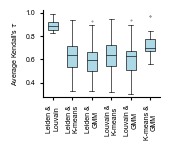

In [42]:
order = ['Leiden &\nLouvain', 'Leiden &\nK-means', 'Leiden &\nGMM', 'Louvain &\nK-means', 'Louvain &\nGMM', 'K-means &\nGMM']
boxplot_data = [avgs[avgs["comparison"] == c]["tau"].values for c in order]

fig, ax = plt.subplots(figsize=(1.8, 1.6))

ax.boxplot(
    boxplot_data, 
    labels=order, 
    patch_artist=True,  # Allows filling the boxes with color
    boxprops=dict(facecolor="lightblue", color="black", linewidth=.45),
    medianprops=dict(color="black", linewidth=.45),
    whiskerprops=dict(color="black", linewidth=.45),
    capprops=dict(color="black", linewidth=.45),
    flierprops=dict(marker="o", markerfacecolor="lightblue", markersize=.95, markeredgecolor='gray', markeredgewidth=0.4)
)
ax.tick_params(axis='both', labelsize=5, length=2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_ylabel("Average Kendall's $\\tau$", fontsize=5)
plt.xticks(rotation=90, fontsize=5)
plt.tight_layout()
# plt.savefig('../publication_figures/clustering_algo_taus.svg', dpi=300, bbox_inches='tight')
plt.show()

## Does network- or centroid-based clustering yield higher scores?

In [31]:
full_vals = pd.concat([df_1, df_2, df_3, df_4, df_5, df_6, df_7, df_8])

In [33]:
full_vals.to_csv('../results/spreadsheets/ablation_analysis_clustering_algorithm.csv', index=False)

In [32]:
group_map = {
    'leiden': 'Network_Based',
    'louvain': 'Network_Based',
    'kmeans': 'Centroid_Based',
    'gmm': 'Centroid_Based'
}

full_vals['meta_group'] = full_vals['clustering_type'].map(group_map)
grouped_max = full_vals.groupby(['Dataset', 'Integration', 'Metric', 'meta_group'])['Value'].max().reset_index()
pivoted = grouped_max.pivot(
    index=['Dataset', 'Integration', 'Metric'], 
    columns='meta_group', 
    values='Value'
).reset_index()

pivoted['Difference'] = pivoted['Network_Based'] - pivoted['Centroid_Based']

In [33]:
pivoted = pivoted[~pivoted.Difference.isna()]
pivoted = pivoted[~np.isinf(pivoted['Difference'].values)]

In [34]:
pivoted_sub = pivoted[~pivoted.Metric.isin(['SEPARATION', 'COMPACT', 'CLUSTCH', 'CLUSTDBI'])]

l = []
for m in ['SEPARATION', 'COMPACT', 'CLUSTCH', 'CLUSTDBI']:
    sub = pivoted[pivoted.Metric == m]
    sub['Difference'] = sub['Difference'] / sub.groupby('Dataset')['Difference'].transform(lambda x: x.abs().max())
    l.append(sub)

/tmp/ipykernel_2191697/307026549.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sub['Difference'] = sub['Difference'] / sub.groupby('Dataset')['Difference'].transform(lambda x: x.abs().max())
/tmp/ipykernel_2191697/307026549.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sub['Difference'] = sub['Difference'] / sub.groupby('Dataset')['Difference'].transform(lambda x: x.abs().max())
/tmp/ipykernel_2191697/307026549.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from 

In [35]:
pivoted_final = pd.concat([pivoted_sub] + l)

In [39]:
pivoted_final['Integration'].nunique()

39

/tmp/ipykernel_2036785/3065839337.py:56: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


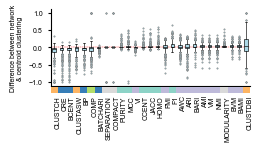

In [37]:
import matplotlib.transforms as mtransforms
from matplotlib.patches import FancyBboxPatch

metric_order = (
    pivoted_final.groupby('Metric')['Difference']
    .median()
    .sort_values(ascending=True)
    .index.tolist()
)

h0 = 'Clusters-as-predictions & KNN'
h1 = 'Logistic regression'
h2 = 'Cluster-label similarity'
h3 = 'Isolated labels & GC'
h4 = 'Cell types as clusters'
h5 = 'Joint bioconservation & batch correction'
h6 = 'Cluster quality 1'
h7 = 'Fine-grained biology'
h8 = 'Cluster quality 2'
k0 = 'Primarily bioconservation'
k1 = 'BASW & SV'
k2 = 'Clustering metrics'
k3 = 'PCR & PROBELR'
k5 = 'Unique metrics'
k6 = 'KNN'
metric_to_group = {
    'fmi': h2, 'awc': h2, 'ari': h2, 'vi': h2, 'nmi': h2, 'ami': h2, 'vm':h2, 
    'bari': h2, 'bami': h2, 'bvm': h2, 
    'isoasw': h3, 'gc': h3, 'isof1': h3, 'isolisi': h3,
    'casw': h4, 'cdbi': h4, 'cch': h4, 
    'blogreg': h1, 'flogreg': h1, 
    'clisi': h0, 'fknn': h0, 'ksim': h0, 'ocs': h0, 'nnmap': h0, 'cnent': h0, 
    'cnentropyw': h0, 'bknn': h0, 'f1': h0, 'mcc': h0, 'jacc': h0, 'purity': h0, 
    'ccent': h0, 'homo': h0, 'arif': h0, 'nmif': h0, 
    'clustch': h6, 'clustasw': h6, 'clustdbi': h6, 
    'comp': h5, 'pptpc': h5, 'pstdb': h5, 
    'ldfdiff': h7, 'agree': h7, 'morani': h7, 'rknn': h7, 'ccc': h7, 
    'scgraph': h7, 'corrmse': h7, 'traj': h7, 'scgraphp': h7, 'scgraphm': h7,
    'modularity': h8, 'compact': h8, 'separation': h8,
    'mix': k6, 'align': k6, 'ilisi': k6, 'bnent': k6, 'kldiv': k6,
    'adgbd': k6, 'kbetall': k6, 'cilisi': k6, 'csms': k6, 'kbet': k6,
    'bras': k5, 'embdiv': k5, 'probe': k5,  'pcr': k3,
    'probelr': k3, 'proberf': k5,
    'bp': k2, 'bcent': k2, 'cre': k2, 'batchari': k2,
    'basw': k1, 'sv': k1,
}
group_to_color = {
    h0: '#8dd3c7', h1: '#ffffb3', h2: '#bebada', h3: '#fb8072', h4: '#80b1d3',
    h6: '#fdb462', h5: '#b3de69', h7: '#fccde5', h8: '#d9d9d9',
    k6: '#e41a1c', k5: '#4daf4a', k3: '#ff7f00', k2: '#377eb8', k1: 'ffff33', k0: '#a65628'
}
fig, ax = plt.subplots(figsize=(2.7, 1.1))

grouped_data = [pivoted_final[pivoted_final['Metric'] == m]['Difference'] for m in metric_order]

ax.boxplot(
    grouped_data,
    labels=metric_order,
    patch_artist=True,  
    boxprops=dict(facecolor="lightblue", color="black", linewidth=.45),
    medianprops=dict(color="black", linewidth=.45),
    whiskerprops=dict(color="black", linewidth=.45),
    capprops=dict(color="black", linewidth=.45),
    flierprops=dict(marker="o", markerfacecolor="lightblue", markersize=.95, markeredgecolor='gray', markeredgewidth=0.4)
)
ax.axhline(0, color='red', linewidth=0.3, linestyle='--', zorder=0)
ax.tick_params(axis='both', labelsize=5, length=2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_ylabel('Difference between network\n& centroid clustering', fontsize=5)
ax.set_xticklabels([])

plt.tight_layout()
fig.canvas.draw()  # finalize layout before adding patches

# --- sizing in points ---
box_h_pt = 4     # height of each color box
box_w_pt = 18    # width of each color box (unused directly, spacing is data-driven)
gap_pt   = 0.5     # flush against the axis

dpi = fig.dpi
pt_to_disp = dpi / 72.0

if len(metric_order) > 1:
    x0_disp = ax.transData.transform((1, ax.get_ylim()[0]))[0]
    x1_disp = ax.transData.transform((2, ax.get_ylim()[0]))[0]
    tick_spacing_disp = x1_disp - x0_disp
else:
    tick_spacing_disp = 20 * pt_to_disp

box_w_disp = tick_spacing_disp * 1

for i, metric in enumerate(metric_order):
    tick_x = i + 1
    grp   = metric_to_group.get(metric.lower(), "Unknown")
    color = group_to_color.get(grp, "gray")

    x_disp, y_disp = ax.transData.transform((tick_x, ax.get_ylim()[0]))

    box_top    = y_disp - gap_pt * pt_to_disp
    box_bottom = box_top - box_h_pt * pt_to_disp
    box_left   = x_disp - box_w_disp / 2
    box_right  = x_disp + box_w_disp / 2

    inv = ax.transAxes.inverted()
    xl, yt = inv.transform((box_left,  box_top))
    xr, yb = inv.transform((box_right, box_bottom))

    rect = FancyBboxPatch(
        (xl, yb), xr - xl, yt - yb,
        boxstyle="square,pad=0",
        transform=ax.transAxes,
        clip_on=False,
        facecolor=color,
        edgecolor="none",
        zorder=5,
    )
    ax.add_patch(rect)

    lx, ly = inv.transform((x_disp, box_bottom - 2 * pt_to_disp))
    ax.text(
        lx, ly, metric,
        transform=ax.transAxes,
        ha='right', va='top',
        fontsize=5,
        rotation=90,
        rotation_mode='anchor',
        clip_on=False,
    )

plt.savefig('../publication_figures/difference_network_centroid_metric.svg', dpi=300, bbox_inches='tight')
plt.show()

### Sub-analysis of metrics per dataset and integration method

i.e., do we see a preference in particular methods or datasets for network- or centroid-based clustering?

In [49]:
clean_df = full_vals[~full_vals['Value'].isna() & ~np.isinf(full_vals['Value'])].copy()
metric_maxes = (
    clean_df.groupby(['Dataset', 'Integration', 'Metric'])['Value']
    .transform('max')
)
top_performers = clean_df[clean_df['Value'] == metric_maxes].copy()
top_performers['is_network'] = top_performers['meta_group'] == 'Network_Based'

metric_level_df = (
    top_performers.groupby(['Dataset', 'Integration', 'Metric'])['is_network']
    .any()
    .astype(int)
    .reset_index()
)

fraction_df = metric_level_df.groupby(['Integration', 'Dataset'])['is_network'].agg(
    n='sum',
    m='size'
).reset_index()

percentage_df = fraction_df.copy()
percentage_df['pct'] = (percentage_df['n'] / percentage_df['m'])
color_matrix = percentage_df.pivot(index='Integration', columns='Dataset', values='pct')

fraction_df['label'] = fraction_df['n'].astype(str) + '/' + fraction_df['m'].astype(str)
label_matrix = fraction_df.pivot(index='Integration', columns='Dataset', values='label')

label_matrix = label_matrix.fillna('')

global_summary = metric_level_df.groupby('Dataset')['is_network'].agg(
    n='sum',
    m='size'
)

global_summary['pct'] = global_summary['n'] / global_summary['m']
global_summary['label'] = global_summary['pct'].astype(str).str[:5]

color_matrix.loc['All Integrations'] = global_summary['pct']
label_matrix.loc['All Integrations'] = global_summary['label']

label_matrix = label_matrix.fillna('')
color_matrix.columns= color_matrix.columns.str.replace('human_pbmc_sequencing_techs', 'human_pbmc_seq_techs')
color_matrix.columns= color_matrix.columns.str.replace('nph_cerebellum', 'nhp_cerebellum')

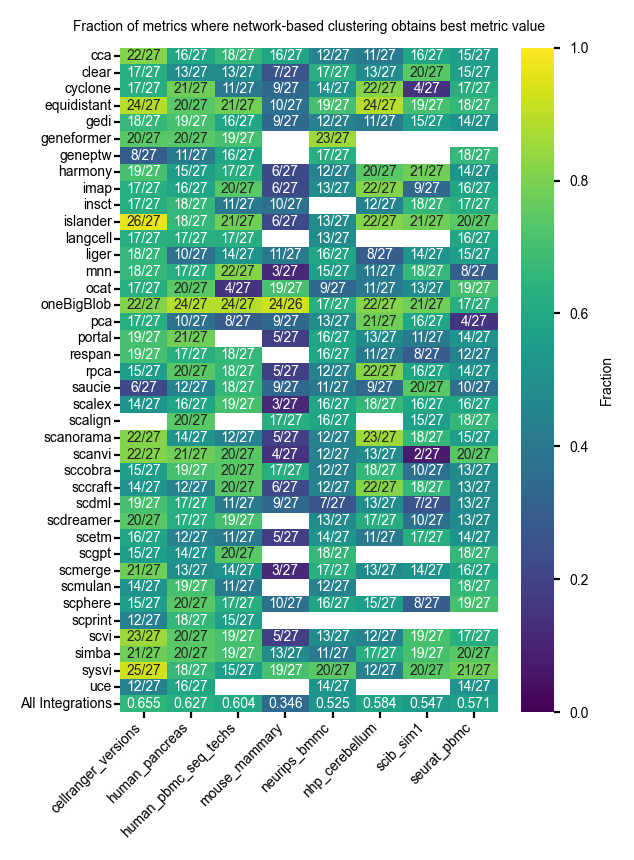

In [50]:
with plt.rc_context({'figure.dpi': 200}):
    fig, ax = plt.subplots(figsize=(3.25, 4.4))

    sns.heatmap(
        color_matrix,
        annot=label_matrix,  # Pass the text matrix here to override the default numbers
        fmt="",              # String formatting must be empty when passing text annotations
        cmap="viridis",
        annot_kws={"fontsize": 5},
        cbar_kws={'label': 'Fraction'},
        vmin=0, vmax=1,
        ax=ax
    )

    # Customizations
    ax.set_title('Fraction of metrics where network-based clustering obtains best metric value', fontsize=5)
    ax.tick_params(axis='both', labelsize=5, length=2, pad=1)
    ax.set_ylabel('')
    ax.set_xlabel('')
    
    ax.set_yticks(np.arange(len(color_matrix)) + 0.5)
    ax.set_yticklabels(color_matrix.index)
    ax.set_xticklabels(color_matrix.columns, rotation=45, ha='right')

    cbar = ax.collections[0].colorbar
    cbar.set_label('Fraction', fontsize=5)
    cbar.ax.tick_params(labelsize=5, length=2)
    plt.tight_layout()
#     plt.savefig('../publication_figures/network_based_better.png', dpi=300, bbox_inches='tight')
    plt.show()

In [51]:
clean_df = full_vals[~full_vals['Value'].isna() & ~np.isinf(full_vals['Value'])].copy()
metric_maxes = (
    clean_df.groupby(['Dataset', 'Integration', 'Metric'])['Value']
    .transform('max')
)
top_performers = clean_df[clean_df['Value'] == metric_maxes].copy()
top_performers['is_network'] = top_performers['meta_group'] == 'Centroid_Based'

metric_level_df = (
    top_performers.groupby(['Dataset', 'Integration', 'Metric'])['is_network']
    .any()
    .astype(int)
    .reset_index()
)

fraction_df = metric_level_df.groupby(['Integration', 'Dataset'])['is_network'].agg(
    n='sum',
    m='size'
).reset_index()

percentage_df = fraction_df.copy()
percentage_df['pct'] = (percentage_df['n'] / percentage_df['m'])
color_matrix = percentage_df.pivot(index='Integration', columns='Dataset', values='pct')

fraction_df['label'] = fraction_df['n'].astype(str) + '/' + fraction_df['m'].astype(str)
label_matrix = fraction_df.pivot(index='Integration', columns='Dataset', values='label')

label_matrix = label_matrix.fillna('')
global_summary = metric_level_df.groupby('Dataset')['is_network'].agg(
    n='sum',
    m='size'
)

global_summary['pct'] = global_summary['n'] / global_summary['m']
global_summary['label'] = global_summary['pct'].astype(str).str[:5]

color_matrix.loc['All Integrations'] = global_summary['pct']
label_matrix.loc['All Integrations'] = global_summary['label']

label_matrix = label_matrix.fillna('')
color_matrix.columns= color_matrix.columns.str.replace('human_pbmc_sequencing_techs', 'human_pbmc_seq_techs')
color_matrix.columns= color_matrix.columns.str.replace('nph_cerebellum', 'nhp_cerebellum')

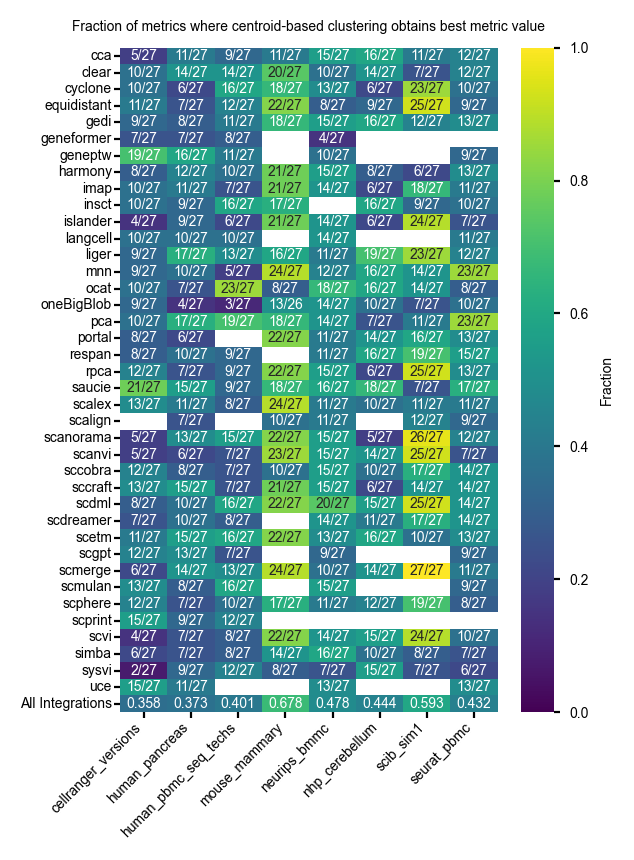

In [52]:
with plt.rc_context({'figure.dpi': 200}):
    fig, ax = plt.subplots(figsize=(3.25, 4.4))

    sns.heatmap(
        color_matrix,
        annot=label_matrix,  # Pass the text matrix here to override the default numbers
        fmt="",              # String formatting must be empty when passing text annotations
        cmap="viridis",
        annot_kws={"fontsize": 5},
        cbar_kws={'label': 'Fraction'},
        vmin=0, vmax=1,
        ax=ax
    )

    # Customizations
    ax.set_title('Fraction of metrics where centroid-based clustering obtains best metric value', fontsize=5)
    ax.tick_params(axis='both', labelsize=5, length=2, pad=1)
    ax.set_ylabel('')
    ax.set_xlabel('')
    
    ax.set_yticks(np.arange(len(color_matrix)) + 0.5)
    ax.set_yticklabels(color_matrix.index)
    ax.set_xticklabels(color_matrix.columns, rotation=45, ha='right')

    cbar = ax.collections[0].colorbar
    cbar.set_label('Fraction', fontsize=5)
    cbar.ax.tick_params(labelsize=5, length=2)
    plt.tight_layout()
#     plt.savefig('../publication_figures/centroid_based_better.png', dpi=300, bbox_inches='tight')

    plt.show()

## Coefficient of variations of metrics under different clustering algorithms

In [53]:
df_full = pd.concat([df_1, df_2, df_3, df_4, df_5, df_6, df_7, df_8])
df_full = df_full[df_full.Metric != 'ISOF1']
df_full.replace([np.inf, -np.inf], np.nan, inplace=True)

In [54]:
cvs = df_full.pivot(index=['Dataset', 'Integration', 'clustering_type'],
                    columns='Metric', values="Value").groupby(['Dataset', 'clustering_type'])[df_full.Metric.unique()].apply(
    lambda x: x.std() / x.mean().abs()
).reset_index()

In [55]:
import matplotlib.ticker as mticker
from scipy.stats import wilcoxon

In [56]:
def plot_cv_metrics(
    df: pd.DataFrame,
    dataset_col: str = "Dataset",
    k_col: str = "clustering_type",
    reference_k = 'leiden',
    ncols: int = 6,
    figsize_per_cell: tuple = (1.1, 1),
    alpha_levels: tuple = (0.05, 0.01, 0.001),
    color: str = "#378ADD",
    adjustment_method: str = "fdr_bh",
):
    """
    Plot small-multiple bar charts of coefficient of variation (CV) vs neighbor_k,
    averaged across datasets, with Wilcoxon signed-rank significance stars
    compared to a reference k value. P-values are adjusted across all
    metric × k comparisons using the specified multiple-testing correction.
    Error bars show ±1 standard error across datasets.
 
    Parameters
    ----------
    df : pd.DataFrame
        Must contain `dataset_col`, `k_col`, and one column per metric.
    dataset_col : str
        Column name identifying datasets.
    k_col : str
        Column name for neighbor_k values.
    reference_k : int
        The k value to test significance against (default 15).
    ncols : int
        Number of columns in the small-multiple grid.
    figsize_per_cell : tuple
        (width, height) in inches for each subplot cell.
    alpha_levels : tuple
        Thresholds for *, **, *** significance (default 0.05, 0.01, 0.001).
    color : str
        Line/marker color.
    adjustment_method : str
        Multiple-testing correction method passed to statsmodels multipletests
        (e.g. 'fdr_bh', 'bonferroni', 'holm'). Default is 'fdr_bh' (Benjamini-Hochberg).
    """
    metric_cols = ordered_metrics
    k_values = ['leiden', 'louvain', 'kmeans', 'gmm']
    n_metrics = len(metric_cols)
    nrows = math.ceil(n_metrics / ncols)
 
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(figsize_per_cell[0] * ncols, figsize_per_cell[1] * nrows),
        constrained_layout=True,
    )
    axes_flat = np.array(axes).flatten()
 
    ref_data = {}
    for metric in metric_cols:
        ref_subset = df[df[k_col] == reference_k][metric].dropna().values
        ref_data[metric] = ref_subset
 
    raw_p_values = {}
    means_per_metric = {}
    stderrs_per_metric = {}
 
    for metric in metric_cols:
        means, stderrs = [], []
        for k in k_values:
            vals = df[df[k_col] == k][metric].dropna().values
            means.append(np.mean(vals))
            stderrs.append(np.std(vals, ddof=1) / np.sqrt(len(vals)))
 
            if k != reference_k and len(vals) >= 2 and len(ref_data[metric]) >= 2:
                ref_vals = ref_data[metric]
                min_len = min(len(vals), len(ref_vals))
                diffs = vals[:min_len] - ref_vals[:min_len]
                if np.any(diffs != 0):
                    _, p = wilcoxon(diffs)
                else:
                    p = 1.0
                raw_p_values[(metric, k)] = p
 
        means_per_metric[metric] = np.array(means)
        stderrs_per_metric[metric] = np.array(stderrs)
 
    keys = list(raw_p_values.keys())
    raw_p_array = np.array([raw_p_values[k] for k in keys])
    _, adj_p_array, _, _ = multipletests(raw_p_array, method=adjustment_method)
    adj_p_values = dict(zip(keys, adj_p_array))
 
    for idx, metric in enumerate(metric_cols):
        ax = axes_flat[idx]
        means = means_per_metric[metric]
        stderrs = stderrs_per_metric[metric]
 
        x = np.arange(len(k_values))
        bars = ax.bar(
            x, means,
            color=color, alpha=0.85,
            width=0.6,
            zorder=3,
        )
 
        # Stars above each bar
        y_range = max(means + stderrs) - min(means - stderrs)
        point_offset = y_range * 0.0001
 
        for i, k in enumerate(k_values):
            if k == reference_k or (metric, k) not in adj_p_values:
                continue
            p = adj_p_values[(metric, k)]
            if p < alpha_levels[2]:
                stars = "***"
            elif p < alpha_levels[1]:
                stars = "**"
            elif p < alpha_levels[0]:
                stars = "*"
            else:
                stars = "ns"
 
            if stars != "ns":
                bar_top = means[i]
                ax.text(x[i], bar_top + point_offset, stars, ha="center", va="bottom",
                        fontsize=9, color="#D85A30", fontweight="bold",
                        clip_on=False)
 
        ax.set_title(metric, fontsize=5, fontweight="medium", pad=6)
        last_row_start = (nrows - 1) * ncols
        is_bottom = last_row_start <= idx < last_row_start + ncols and idx < n_metrics
        is_left = idx % ncols == 0
        if is_bottom:
            ax.set_xlabel("Clustering algorithm", fontsize=5)
        if is_left:
            ax.set_ylabel("CV", fontsize=5)
        ax.set_xticks(x)
        ax.set_xticklabels(k_values)
        ax.tick_params(labelsize=8)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_linewidth(0.45)
        ax.spines["bottom"].set_linewidth(0.45)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
        ax.tick_params(axis='x', labelrotation=45)

        fig.canvas.draw()

    for idx in range(n_metrics, len(axes_flat)):
        axes_flat[idx].set_visible(False)
    return fig

/tmp/ipykernel_3719369/67084447.py:3: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


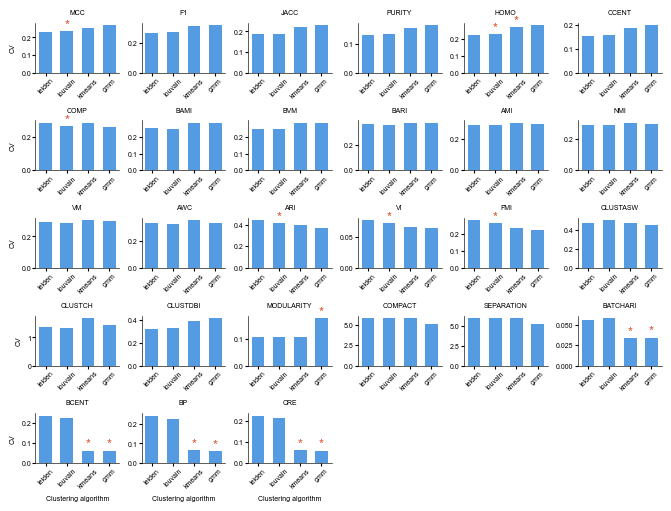

In [57]:
fig = plot_cv_metrics(cvs)
# fig.savefig('../publication_figures/clustering_algorithm_cvs.png', dpi=300, bbox_inches='tight')
fig.show()